<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C14_Notebook-18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background: linear-gradient(135deg, #6E4B9F 0%, #35BEAE 100%); border-radius: 14px; padding: 28px 32px; margin-bottom: 10px;">
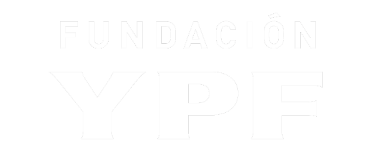
<h2 style="color: #FFFFFF; margin-top: 18px; margin-bottom: 0; font-family: sans-serif;">Fundacion YPF | Data Science</h2>
</div>

# Notebook 18: Practica de Regresion y Clasificacion

**Clase 14**

## Indice

- **Parte 0**: Introduccion y objetivos
- **Parte 1**: Regresion, prediccion del precio de autos usados
- **Parte 2**: Clasificacion, prediccion de recurrencia de cancer de mama
- **Parte 3**: Desafio para las salas


## Parte 0: Introduccion y objetivos

En la Clase 12 y en la Clase 13 vimos los algoritmos mas comunes de regresion y clasificacion: Regresion Lineal, Arboles de Decision, Random Forest, Regresion Logistica, K Nearest Neighbors (KNN) y Support Vector Machine (SVM).

En esta notebook practicamos el ajuste de esos modelos de punta a punta, repasando lo trabajado en las Notebooks 16 y 17: cargar los datos, explorarlos, limpiarlos, prepararlos para el modelo, ajustar varios algoritmos y comparar sus resultados.

Vamos a trabajar con dos datasets distintos:

- **Regresion**: un dataset de venta de autos usados, donde el objetivo es predecir el precio de venta.
- **Clasificacion**: el dataset de cancer de mama que ya usamos en las clases anteriores, donde el objetivo es predecir si hubo recurrencia de la enfermedad.

Empecemos importando las librerias que vamos a necesitar.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

pd.set_option('display.max_columns', None)


## Parte 1: Regresion, prediccion del precio de autos usados

Vamos a trabajar con un dataset de publicaciones de venta de autos usados. El objetivo es predecir el **precio de venta** (`price`) a partir de las caracteristicas del vehiculo, como el tipo de carroceria, el anio de registro, la potencia, el kilometraje, la marca, entre otras.

Este es un dataset real, asi que va a tener valores faltantes y errores de carga que vamos a tener que limpiar antes de poder entrenar un modelo.

In [ ]:
from google.colab import drive
drive.mount ('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.1 Carga y exploracion de datos

In [ ]:
ruta = '/content/drive/MyDrive/venta_autos.csv'
df_autos = pd.read_csv(ruta, encoding='latin1')
df_autos.head(50)


,dateCrawled,name,seller,offerType,price,abtest,vehicleType,yearOfRegistration,gearbox,powerPS,model,kilometer,monthOfRegistration,fuelType,brand,notRepairedDamage,dateCreated,postalCode,lastSeen
0,30/03/2016 13:51,Zu_verkaufen,private,offer,4450,test,limousine,2003,manual,150,3er,150000,3,diesel,bmw,NaN,30/03/2016 0:00,20257,7/4/2016 4:44
1,7/3/2016 9:54,Volvo_XC90_2.4D_Summum,private,offer,13299,control,suv,2005,manual,163,xc_reihe,150000,6,diesel,volvo,no,7/3/2016 0:00,88045,26/03/2016 13:17
2,1/4/2016 0:57,Volkswagen_Touran,private,offer,3200,test,bus,2003,manual,101,touran,150000,11,diesel,volkswagen,NaN,31/03/2016 0:00,27449,1/4/2016 8:40
3,19/03/2016 17:50,Seat_Ibiza_1.4_16V_Reference,private,offer,4500,control,small car,2006,manual,86,ibiza,60000,12,petrol,seat,no,19/03/2016 0:00,34537,7/4/2016 4:44
4,16/03/2016 14:51,Volvo_XC90_D5_Aut._RDesign_R_Design_AWD_GSHD_S...,private,offer,18750,test,suv,2008,automatic,185,xc_reihe,150000,11,diesel,volvo,no,16/03/2016 0:00,55270,1/4/2016 23:18
5,2/4/2016 12:51,VW_Passat_35i_Facelift_Limousine_TÃV_Neu,private,offer,988,test,limousine,1995,manual,90,passat,150000,2,petrol,volkswagen,no,2/4/2016 0:00,26826,2/4/2016 12:51
6,3/4/2016 11:06,Opel_astra,private,offer,400,test,station wagon,1996,manual,0,astra,150000,5,petrol,opel,NaN,3/4/2016 0:00,56422,6/4/2016 16:47
7,24/03/2016 15:52,Mercedes_Benz_CLK_Coupe_200,private,offer,1399,test,coupe,1997,manual,136,clk,150000,11,petrol,mercedes_benz,no,24/03/2016 0:00,13353,27/03/2016 12:45
8,28/03/2016 14:40,Vectra_C_Caravan_1_8_Edition_Facelift_m_AHK_In...,private,offer,4680,test,station wagon,2005,manual,122,vectra,150000,12,petrol,opel,no,28/03/2016 0:00,28307,6/4/2016 18:19
9,5/4/2016 11:38,Skoda_Octavia_2.0_TDI_DSG_Elegance,private,offer,8340,test,limousine,2005,automatic,140,octavia,125000,4,diesel,skoda,no,5/4/2016 0:00,16761,5/4/2016 11:38


In [ ]:
print('Filas y columnas:', df_autos.shape)
df_autos.info()

Filas y columnas: (50001, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   dateCrawled          50001 non-null  object
 1   name                 50001 non-null  object
 2   seller               50001 non-null  object
 3   offerType            50001 non-null  object
 4   price                50001 non-null  int64 
 5   abtest               50001 non-null  object
 6   vehicleType          44813 non-null  object
 7   yearOfRegistration   50001 non-null  int64 
 8   gearbox              47177 non-null  object
 9   powerPS              50001 non-null  int64 
 10  model                47243 non-null  object
 11  kilometer            50001 non-null  int64 
 12  monthOfRegistration  50001 non-null  int64 
 13  fuelType             45498 non-null  object
 14  brand                50001 non-null  object
 15  notRepairedDamage    40

In [ ]:
df_autos.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   dateCrawled          50001 non-null  object
 1   name                 50001 non-null  object
 2   seller               50001 non-null  object
 3   offerType            50001 non-null  object
 4   price                50001 non-null  int64 
 5   abtest               50001 non-null  object
 6   vehicleType          44813 non-null  object
 7   yearOfRegistration   50001 non-null  int64 
 8   gearbox              47177 non-null  object
 9   powerPS              50001 non-null  int64 
 10  model                47243 non-null  object
 11  kilometer            50001 non-null  int64 
 12  monthOfRegistration  50001 non-null  int64 
 13  fuelType             45498 non-null  object
 14  brand                50001 non-null  object
 15  notRepairedDamage    40285 non-null  object
 16  date

Miremos con mas detalle las columnas numericas que vamos a usar como predictoras y como variable objetivo. Prestale atencion al minimo y al maximo de cada una: ¿te parecen valores razonables para un auto usado?

In [ ]:
df_autos[['price', 'yearOfRegistration', 'powerPS', 'kilometer']].describe()


,price,yearOfRegistration,powerPS,kilometer
count,5.000100e+04,50001.000000,50001.000000,50001.000000
mean,6.559865e+03,2005.544229,116.496130,125613.687726
std,8.581847e+04,122.991832,230.567709,40205.234483
min,0.000000e+00,1000.000000,0.000000,5000.000000
25%,1.150000e+03,1999.000000,69.000000,125000.000000
50%,2.950000e+03,2003.000000,105.000000,150000.000000
75%,7.190000e+03,2008.000000,150.000000,150000.000000
max,1.234568e+07,9999.000000,19312.000000,150000.000000


Como te habras dado cuenta, hay valores que no tienen sentido: autos con `price` en 0, anios de registro como 1000 o 9999, y potencias (`powerPS`) en 0 o en varios miles de caballos de fuerza. Antes de entrenar cualquier modelo, tenemos que limpiar estos datos.

### 1.2 Limpieza de datos

Vamos a quedarnos solo con los datos que tienen valores razonables:

- `price` entre 500 y 100.000
- `yearOfRegistration` entre 1950 y 2016 (el dataset fue relevado en 2016)
- `powerPS` entre 40 y 600 caballos de fuerza

Ademas, hay columnas categoricas con valores faltantes (`vehicleType`, `gearbox`, `fuelType`, `notRepairedDamage`). En vez de eliminar esas filas, las vamos a completar con la categoria `"desconocido"`, para no perder informacion de las demas columnas.

In [ ]:
#Filtramos los valores fuera de rango en price, yearOfRegistration y powerPS
df_autos = df_autos[(df_autos['price'] >= 500) & (df_autos['price'] <= 100000)]
df_autos = df_autos[(df_autos['yearOfRegistration'] >= 1950) & (df_autos['yearOfRegistration'] <= 2016)]
df_autos = df_autos[(df_autos['powerPS'] >= 40) & (df_autos['powerPS'] <= 600)]

print('Filas luego de filtrar valores fuera de rango:', df_autos.shape[0])


Filas luego de filtrar valores fuera de rango: 39604


In [ ]:
#Completamos los valores faltantes de las columnas categoricas con "desconocido"
columnas_categoricas = ['vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']

for columna in columnas_categoricas:
    df_autos[columna] = df_autos[columna].fillna('desconocido')

df_autos[columnas_categoricas].isna().sum()


,0
vehicleType,0
gearbox,0
fuelType,0
notRepairedDamage,0


### 1.3 Seleccion de variables y codificacion

Nos quedamos solo con las columnas que le van a aportar informacion util al modelo. Descartamos columnas como `dateCrawled`, `name`, `seller`, `offerType`, `abtest`, `model`, `dateCreated`, `postalCode` y `lastSeen`, que no describen al vehiculo en si o que tienen demasiadas categorias distintas para esta primera aproximacion.

Los modelos de Machine Learning necesitan que todas las variables sean numericas, asi que las columnas categoricas (`vehicleType`, `gearbox`, `fuelType`, `brand`, `notRepairedDamage`) las transformamos con **one-hot encoding**, usando `pd.get_dummies`.

In [ ]:
columnas_a_usar = ['price', 'vehicleType', 'yearOfRegistration', 'gearbox', 'powerPS',
                   'kilometer', 'monthOfRegistration', 'fuelType', 'brand', 'notRepairedDamage']

df_autos_modelo = df_autos[columnas_a_usar].copy()

df_autos_encoded = pd.get_dummies(df_autos_modelo,
                                   columns=['vehicleType', 'gearbox', 'fuelType', 'brand', 'notRepairedDamage'],
                                   drop_first=True)

print('Forma del dataset luego de codificar:', df_autos_encoded.shape)
df_autos_encoded.head()


Forma del dataset luego de codificar: (39604, 59)


,price,yearOfRegistration,powerPS,kilometer,monthOfRegistration,vehicleType_cabrio,vehicleType_coupe,vehicleType_limousine,vehicleType_others,vehicleType_small car,vehicleType_station wagon,vehicleType_suv,gearbox_manual,fuelType_diesel,fuelType_electro,fuelType_hybrid,fuelType_lpg,fuelType_other,fuelType_petrol,brand_audi,brand_bmw,brand_chevrolet,brand_chrysler,brand_citroen,brand_dacia,brand_daewoo,brand_daihatsu,brand_fiat,brand_ford,brand_honda,brand_hyundai,brand_jaguar,brand_jeep,brand_kia,brand_lada,brand_lancia,brand_land_rover,brand_mazda,brand_mercedes_benz,brand_mini,brand_mitsubishi,brand_nissan,brand_opel,brand_peugeot,brand_porsche,brand_renault,brand_rover,brand_saab,brand_seat,brand_skoda,brand_smart,brand_sonstige_autos,brand_subaru,brand_suzuki,brand_toyota,brand_trabant,brand_volkswagen,brand_volvo,notRepairedDamage_yes
0,4450,2003,150,150000,3,False,False,True,False,False,False,False,True,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,13299,2005,163,150000,6,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,3200,2003,101,150000,11,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
3,4500,2006,86,60000,12,False,False,False,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
4,18750,2008,185,150000,11,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


### 1.4 Division en train y test

Separamos las variables predictoras (`X`) de la variable objetivo (`y`), y dividimos el dataset en un conjunto de entrenamiento (80%) y uno de testeo (20%).

In [ ]:
X_autos = df_autos_encoded.drop(columns=['price'])
y_autos = df_autos_encoded['price']

X_train_autos, X_test_autos, y_train_autos, y_test_autos = train_test_split(
    X_autos, y_autos, test_size=0.2, random_state=42
)

print('Train:', X_train_autos.shape)
print('Test:', X_test_autos.shape)


Train: (31683, 58)
Test: (7921, 58)


### 1.5 Ajuste de modelos de regresion

Ahora si, entrenamos tres modelos distintos sobre los mismos datos y comparamos como se comportan:

- **Regresion Lineal**
- **Arbol de Decision**
- **Random Forest**

In [ ]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_autos, y_train_autos)


LinearRegression()

In [ ]:
modelo_arbol = DecisionTreeRegressor(max_depth=8, random_state=42)
modelo_arbol.fit(X_train_autos, y_train_autos)


DecisionTreeRegressor(max_depth=8, random_state=42)

In [ ]:
modelo_rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train_autos, y_train_autos)


RandomForestRegressor(max_depth=10, n_jobs=-1, random_state=42)

### 1.6 Evaluacion y comparacion de modelos

Para comparar los tres modelos usamos tres metricas de regresion:

- **MAE** (Mean Absolute Error): el error promedio, en las mismas unidades que el precio.
- **RMSE** (Root Mean Squared Error): tambien en unidades de precio, pero penaliza mas fuerte los errores grandes.
- **R2**: que porcentaje de la variabilidad del precio explica el modelo (cuanto mas cerca de 1, mejor).

In [ ]:
modelos_regresion = {
    'Regresion Lineal': modelo_lineal,
    'Arbol de Decision': modelo_arbol,
    'Random Forest': modelo_rf
}

resultados_regresion = []

for nombre, modelo in modelos_regresion.items():
    predicciones = modelo.predict(X_test_autos)
    mae = mean_absolute_error(y_test_autos, predicciones)
    rmse = mean_squared_error(y_test_autos, predicciones) ** 0.5
    r2 = r2_score(y_test_autos, predicciones)
    resultados_regresion.append({'Modelo': nombre, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

df_resultados_regresion = pd.DataFrame(resultados_regresion)
df_resultados_regresion


,Modelo,MAE,RMSE,R2
0,Regresion Lineal,2869.848431,4600.366101,0.656620
1,Arbol de Decision,1948.219759,3677.829946,0.780531
2,Random Forest,1666.945940,3128.962890,0.841149


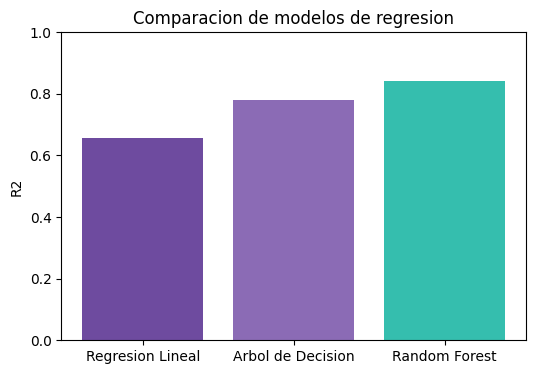

In [ ]:
plt.figure(figsize=(6, 4))
plt.bar(df_resultados_regresion['Modelo'], df_resultados_regresion['R2'], color=['#6E4B9F', '#8B6BB5', '#35BEAE'])
plt.ylabel('R2')
plt.title('Comparacion de modelos de regresion')
plt.ylim(0, 1)
plt.show()


**Para pensar y discutir en el grupo:** ¿Cual de los tres modelos tuvo mejor desempenio? ¿Te parece razonable que el Random Forest le gane a un unico Arbol de Decision? ¿Que pasaria si le sumamos la columna `model`, con muchas mas categorias?

## Parte 2: Clasificacion, prediccion de recurrencia de cancer de mama

Volvemos a trabajar con el dataset `cancer_mamario.csv`, que ya usamos en las Notebooks 16 y 17. Esta vez el objetivo es armar el pipeline completo: desde la carga de los datos hasta la comparacion de varios modelos de clasificacion.

La variable objetivo es `class`, que indica si hubo o no recurrencia de la enfermedad (`recurrence-events` o `no-recurrence-events`).

### 2.1 Carga y exploracion de datos

In [ ]:
df_cancer = pd.read_csv('cancer_mamario.csv')
df_cancer.head()


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [ ]:
df_cancer['target'].value_counts()

,count
target,
0,201
1,85


Fijate que las clases no estan balanceadas: hay muchos mas casos de `no-recurrence-events` que de `recurrence-events`. Vamos a tenerlo en cuenta mas adelante, al elegir la division en train y test y al interpretar las metricas.

### 2.2 Limpieza de datos

En este dataset los valores faltantes no aparecen como `NaN`, sino como el caracter `"?"`. Antes de poder detectarlos con `isna()`, tenemos que reemplazarlos.

In [ ]:
df_cancer = df_cancer.replace('?', np.nan)
df_cancer.isna().sum()


,0
age,0
menopause,0
tumor-size,0
inv-nodes,0
node-caps,0
deg-malig,0
breast,0
breast-quad,0
irradiat,0
target,0


Solo dos columnas tienen valores faltantes, y son pocos casos. En vez de eliminar esas filas, las completamos con la moda (el valor mas frecuente) de cada columna.

In [ ]:
df_cancer['node-caps'] = df_cancer['node-caps'].fillna(df_cancer['node-caps'].mode()[0])
df_cancer['breast-quad'] = df_cancer['breast-quad'].fillna(df_cancer['breast-quad'].mode()[0])

df_cancer.isna().sum().sum()


np.int64(0)

### 2.3 Codificacion de variables y variable objetivo

Convertimos la variable objetivo en binaria (1 si hubo recurrencia, 0 si no), y codificamos las variables predictoras categoricas con `pd.get_dummies`, igual que hicimos en la Parte 1.

In [ ]:
if 'class' in df_cancer.columns:
    df_cancer['target'] = (df_cancer['class'] == 'recurrence-events').astype(int)
    df_cancer = df_cancer.drop(columns=['class'])

columnas_categoricas_cancer = ['age', 'menopause', 'tumor-size', 'inv-nodes', 'node-caps', 'breast', 'breast-quad', 'irradiat']

df_cancer_encoded = pd.get_dummies(df_cancer, columns=columnas_categoricas_cancer, drop_first=True)

print('Forma del dataset luego de codificar:', df_cancer_encoded.shape)
df_cancer_encoded.head()

Forma del dataset luego de codificar: (286, 32)


,deg-malig,target,age_30-39,age_40-49,age_50-59,age_60-69,age_70-79,menopause_lt40,menopause_premeno,tumor-size_10-14,tumor-size_15-19,tumor-size_20-24,tumor-size_25-29,tumor-size_30-34,tumor-size_35-39,tumor-size_40-44,tumor-size_45-49,tumor-size_5-9,tumor-size_50-54,inv-nodes_12-14,inv-nodes_15-17,inv-nodes_24-26,inv-nodes_3-5,inv-nodes_6-8,inv-nodes_9-11,node-caps_yes,breast_right,breast-quad_left_low,breast-quad_left_up,breast-quad_right_low,breast-quad_right_up,irradiat_yes
0,3,0,True,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,2,0,False,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False
2,2,0,False,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
3,2,0,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False
4,2,0,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False


### 2.4 Division en train, test y escalado

Usamos `stratify=y` para que la proporcion de recurrencia se mantenga parecida en train y en test, dado el desbalance de clases que vimos antes.

Ademas, KNN y SVM son modelos sensibles a la escala de las variables, asi que estandarizamos los datos con `StandardScaler` antes de entrenarlos.

In [ ]:
X_cancer = df_cancer_encoded.drop(columns=['target'])
y_cancer = df_cancer_encoded['target']

X_train_cancer, X_test_cancer, y_train_cancer, y_test_cancer = train_test_split(
    X_cancer, y_cancer, test_size=0.25, random_state=42, stratify=y_cancer
)

escalador = StandardScaler()
X_train_cancer_esc = escalador.fit_transform(X_train_cancer)
X_test_cancer_esc = escalador.transform(X_test_cancer)

print('Train:', X_train_cancer.shape)
print('Test:', X_test_cancer.shape)


Train: (214, 31)
Test: (72, 31)


### 2.5 Ajuste de modelos de clasificacion

Entrenamos tres modelos sobre los datos ya escalados:

- **Regresion Logistica**
- **K Nearest Neighbors** (con k=5)
- **Support Vector Machine** (con kernel RBF)

In [ ]:
modelo_logistica = LogisticRegression(max_iter=1000)
modelo_logistica.fit(X_train_cancer_esc, y_train_cancer)


LogisticRegression(max_iter=1000)

In [ ]:
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train_cancer_esc, y_train_cancer)


KNeighborsClassifier()

In [ ]:
modelo_svm = SVC(kernel='rbf', random_state=42)
modelo_svm.fit(X_train_cancer_esc, y_train_cancer)


SVC(random_state=42)

### 2.6 Evaluacion y comparacion de modelos

Para clasificacion usamos otro grupo de metricas:

- **Accuracy**: proporcion total de aciertos.
- **Precision**: de los casos que el modelo predijo como recurrencia, cuantos lo eran realmente.
- **Recall**: de los casos que realmente eran recurrencia, cuantos detecto el modelo.
- **F1**: un promedio entre precision y recall.

En un problema desbalanceado como este, el accuracy solo no alcanza para saber si el modelo es bueno: hay que mirar tambien precision y recall.

In [ ]:
modelos_clasificacion = {
    'Regresion Logistica': modelo_logistica,
    'KNN (k=5)': modelo_knn,
    'SVM (kernel rbf)': modelo_svm
}

resultados_clasificacion = []

for nombre, modelo in modelos_clasificacion.items():
    predicciones = modelo.predict(X_test_cancer_esc)
    accuracy = accuracy_score(y_test_cancer, predicciones)
    precision = precision_score(y_test_cancer, predicciones)
    recall = recall_score(y_test_cancer, predicciones)
    f1 = f1_score(y_test_cancer, predicciones)
    resultados_clasificacion.append({'Modelo': nombre, 'Accuracy': accuracy, 'Precision': precision,
                                      'Recall': recall, 'F1': f1})

df_resultados_clasificacion = pd.DataFrame(resultados_clasificacion)
df_resultados_clasificacion


,Modelo,Accuracy,Precision,Recall,F1
0,Regresion Logistica,0.638889,0.352941,0.285714,0.315789
1,KNN (k=5),0.694444,0.428571,0.142857,0.214286
2,SVM (kernel rbf),0.680556,0.400000,0.190476,0.258065


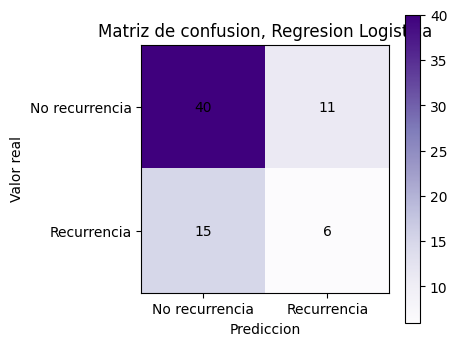

In [ ]:
#Matriz de confusion del modelo de Regresion Logistica
predicciones_logistica = modelo_logistica.predict(X_test_cancer_esc)
matriz_confusion = confusion_matrix(y_test_cancer, predicciones_logistica)

plt.figure(figsize=(4, 4))
plt.imshow(matriz_confusion, cmap='Purples')
plt.title('Matriz de confusion, Regresion Logistica')
plt.xlabel('Prediccion')
plt.ylabel('Valor real')
plt.xticks([0, 1], ['No recurrencia', 'Recurrencia'])
plt.yticks([0, 1], ['No recurrencia', 'Recurrencia'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz_confusion[i, j], ha='center', va='center', color='black')
plt.colorbar()
plt.show()


**Para pensar y discutir en el grupo:** ¿Cual modelo tuvo mejor recall para detectar la clase `recurrencia`? ¿Por que puede ser mas importante el recall que el accuracy en un problema como este? ¿Que otras variables del dataset original te parece que podrian ayudar a mejorar la deteccion?

## Parte 3: Desafio para las salas

Llego tu turno de poner en practica lo que vimos. Trabajando en tu grupo, completa el codigo de las celdas siguientes.

**Consigna 1 (Regresion):** Volve a entrenar el Random Forest de la Parte 1, pero probando con otro valor de `max_depth`. ¿Mejora o empeora el R2 en el conjunto de test?

In [ ]:
modelo_rf_desafio = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
modelo_rf_desafio.fit(X_train_autos, y_train_autos)

predicciones_desafio = modelo_rf_desafio.predict(X_test_autos)
r2_desafio = r2_score(y_test_autos, predicciones_desafio)
print('R2 con el nuevo max_depth:', r2_desafio)

R2 con el nuevo max_depth: 0.8551117919279154


**Consigna 2 (Clasificacion):** Entrena un Arbol de Decision para el problema de clasificacion del cancer de mama (usa `DecisionTreeClassifier`) y calcula su accuracy, precision, recall y F1 sobre el conjunto de test. ¿Como se compara contra los tres modelos que ya entrenamos?

In [ ]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol_cancer = DecisionTreeClassifier(random_state=42)
modelo_arbol_cancer.fit(X_train_cancer_esc, y_train_cancer)

predicciones_arbol_cancer = modelo_arbol_cancer.predict(X_test_cancer_esc)

accuracy = accuracy_score(y_test_cancer, predicciones_arbol_cancer)
precision = precision_score(y_test_cancer, predicciones_arbol_cancer)
recall = recall_score(y_test_cancer, predicciones_arbol_cancer)
f1 = f1_score(y_test_cancer, predicciones_arbol_cancer)

print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')

Accuracy: 0.6667
Precision: 0.4211
Recall: 0.3810
F1 Score: 0.4000


**Consigna 3:** Si tu grupo ya eligio el dataset para el proyecto final, empiecen a aplicar sobre el este mismo recorrido: cargar los datos, explorarlos, limpiarlos, codificar las variables categoricas, dividir en train y test, y ajustar una primera version de un modelo de regresion o de clasificacion, segun corresponda a su problema.